### Case Study 4: E-Commerce Customer Segmentation - Apply K-Means and DBSCAN to an RFM (Recency, Frequency, Monetary) dataset from an online retailer. Reduce dimensions with PCA, visualize.

**Dataset:** `online_retail_clean.csv` from Mathew K Analytics.


In [31]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA

%matplotlib inline

In [32]:
# 2. Load the dataset
file_path = "online_retail_clean.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head(20))

Dataset shape: (391150, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,54.08


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 391150 entries, 0 to 391149
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    391150 non-null  int64  
 1   StockCode    391150 non-null  str    
 2   Description  391150 non-null  str    
 3   Quantity     391150 non-null  int64  
 4   InvoiceDate  391150 non-null  str    
 5   UnitPrice    391150 non-null  float64
 6   CustomerID   391150 non-null  int64  
 7   Country      391150 non-null  str    
 8   Revenue      391150 non-null  float64
dtypes: float64(2), int64(3), str(4)
memory usage: 26.9 MB


In [33]:
# 4. Check invoice frequency
df["InvoiceNo"].value_counts().head(10)

InvoiceNo
576339    541
579196    532
580727    528
578270    441
573576    434
567656    420
567183    391
575607    376
571441    363
570488    352
Name: count, dtype: int64

In [ ]:
# 5. Check missing values
df.isna().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

In [6]:
df = df.reset_index(drop=True)
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [36]:
duplicates = df[df.duplicated()]
display(duplicates)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue


In [37]:
df.describe()

,InvoiceNo,Quantity,UnitPrice,CustomerID,Revenue
count,391150.000000,391150.000000,391150.000000,391150.000000,391150.000000
mean,560592.908268,13.145300,2.874372,15295.171456,22.337281
std,13087.235691,180.807831,4.284738,1710.339033,310.932442
min,536365.000000,1.000000,0.040000,12346.000000,0.060000
25%,549235.000000,2.000000,1.250000,13969.000000,4.950000
50%,561875.000000,6.000000,1.950000,15159.000000,11.900000
75%,572062.000000,12.000000,3.750000,16794.000000,19.800000
max,581587.000000,80995.000000,649.500000,18287.000000,168469.600000


In [38]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,391150.0,NaN,NaN,NaN,560592.908268,13087.235691,536365.0,549235.0,561875.0,572062.0,581587.0
StockCode,391150,3659,85123A,2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,391150,3871,WHITE HANGING HEART T-LIGHT HOLDER,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,391150.0,NaN,NaN,NaN,13.1453,180.807831,1.0,2.0,6.0,12.0,80995.0
InvoiceDate,391150,17166,2011-11-14 15:27:00,541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,391150.0,NaN,NaN,NaN,2.874372,4.284738,0.04,1.25,1.95,3.75,649.5
CustomerID,391150.0,NaN,NaN,NaN,15295.171456,1710.339033,12346.0,13969.0,15159.0,16794.0,18287.0
Country,391150,37,United Kingdom,348872,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,391150.0,NaN,NaN,NaN,22.337281,310.932442,0.06,4.95,11.9,19.8,168469.6


In [ ]:
#9. Categorical columns
for column in df.select_dtypes(include=["object"]).columns:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].nunique(dropna=True))
    print("Example values:", df[column].dropna().unique()[:10])


Column: StockCode
Unique values: 3659
Example values: <StringArray>
['85123A',  '71053', '84406B', '84029G', '84029E',  '22752',  '21730',
  '22633',  '22632',  '84879']
Length: 10, dtype: str

Column: Description
Unique values: 3871
Example values: <StringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',       'ASSORTED COLOUR BIRD ORNAMENT']
Length: 10, dtype: str

Column: InvoiceDate
Unique values: 17166
Example values: <StringArray>
['2010-12-01 08:26:00', '2010-12-01 08:28:00', '2010-12-01 08:34:00',
 '2010-12-01 08:35:00', '2010-12-01 08:45:00', '2010-12-01 09:00:00',
 '2010-12-01 09:01:00', '2010-12-01 09:02:00', '2010-12-01 09:09:00',
 '2010-12-01 09:32:00']
Length: 10,

/var/folders/4j/nj3nl86d11s1x5ld6j6_r2240000gn/T/ipykernel_42002/3981890905.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include=["object"]).columns:


In [ ]:
# Numeric transaction columns for outlier detection 
num_df = df[numeric_columns].copy()
num_df.describe()

,Quantity,UnitPrice,Revenue
count,391150.000000,391150.000000,391150.000000
mean,13.145300,2.874372,22.337281
std,180.807831,4.284738,310.932442
min,1.000000,0.040000,0.060000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,11.900000
75%,12.000000,3.750000,19.800000
max,80995.000000,649.500000,168469.600000


In [ ]:
# Outliers detection using the IQR method
def detect_outliers(column):
    q1 = column.quantile(0.25)
    q3 = column.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return column[(column < lower_bound) | (column > upper_bound)]

outliers_dict = {}
for column in num_df.columns:
    outliers_dict[column] = detect_outliers(num_df[column])

outlier_summary = pd.DataFrame({
    "Column": list(outliers_dict.keys()),
    "Outlier_Count": [len(values) for values in outliers_dict.values()]
})
display(outlier_summary)

for column, outliers in outliers_dict.items():
    if not outliers.empty:
        print(f"\n{column}: {len(outliers)} detected outliers")
        print(outliers.head(10).to_list())

,Column,Outlier_Count
0,Quantity,25594
1,UnitPrice,32781
2,Revenue,30484



Quantity: 25594 detected outliers
[32, 48, 36, 80, 32, 48, 64, 120, 48, 96]

UnitPrice: 32781 detected outliers
[7.65, 9.95, 7.95, 7.95, 7.65, 10.95, 7.65, 14.95, 14.95, 16.95]

Revenue: 30484 detected outliers
[54.08, 90.0, 90.0, 45.0, 53.1, 70.80000000000001, 46.8, 46.8, 46.8, 70.80000000000001]


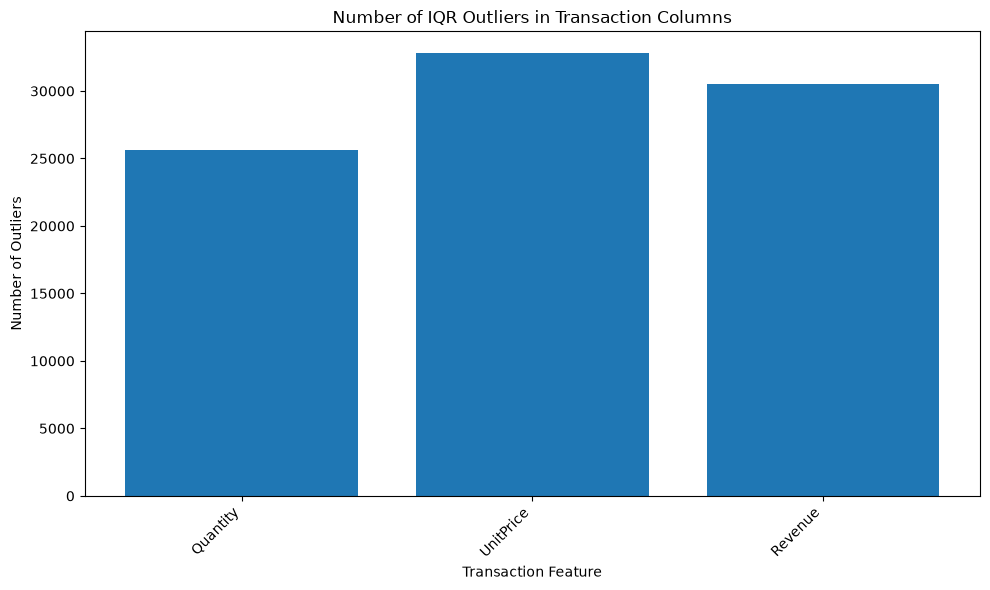

In [ ]:
#Visualizing the number of outliers
plt.figure(figsize=(10, 6))
plt.bar(outlier_summary["Column"], outlier_summary["Outlier_Count"])
plt.title("Number of IQR Outliers in Transaction Columns")
plt.xlabel("Transaction Feature")
plt.ylabel("Number of Outliers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Preprocess the transaction data

The file is already a cleaned retail dataset, but these checks make the notebook reproducible: convert dates and numeric fields, remove exact duplicate rows, remove records without a usable customer/date/invoice, exclude cancelled invoices, and keep only positive-quantity, positive-price purchases. The IQR outliers above are **reported but not automatically deleted or capped**; unusually large purchases can be genuine customer behavior.

In [13]:
clean_df = df.copy()

clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"], errors="coerce")
clean_df["CustomerID"] = pd.to_numeric(clean_df["CustomerID"], errors="coerce")

clean_df = clean_df.drop_duplicates()
clean_df = clean_df.dropna(subset=["CustomerID", "InvoiceDate", "InvoiceNo"])

clean_df = clean_df[
    ~clean_df["InvoiceNo"].astype(str).str.strip().str.upper().str.startswith("C") &
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
]

clean_df["Revenue"] = clean_df["Quantity"] * clean_df["UnitPrice"]
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")
clean_df = clean_df.reset_index(drop=True)

print("Final cleaned transaction shape:", clean_df.shape)
display(clean_df.head())

Final cleaned transaction shape: (391150, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [42]:
# Data after cleaning/preprocessing
display(clean_df.isna().sum().to_frame("Missing values"))
print("Exact duplicate rows after preprocessing:", clean_df.duplicated().sum())
print("Unique customers:", clean_df["CustomerID"].nunique())
print("Unique invoices:", clean_df["InvoiceNo"].nunique())

,Missing values
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
Revenue,0


Exact duplicate rows after preprocessing: 0
Unique customers: 4334
Unique invoices: 18402


## Create the RFM table

- **Recency:** days since the customer's most recent purchase, measured relative to one day after the latest date in the cleaned dataset.
- **Frequency:** number of distinct invoices for the customer.
- **Monetary:** sum of `Revenue` for the customer.

In [15]:
snapshot_date = clean_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm_table = clean_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (snapshot_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM table shape:", rfm_table.shape)
display(rfm_table.head(20))

RFM table shape: (4334, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1437.24
3,12349,19,1,1457.55
4,12350,310,1,294.40
5,12352,36,7,1385.74
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2487.43


In [ ]:
rfm_table_cleaned = rfm_table.dropna(subset=["Recency", "Frequency", "Monetary"]).copy()
rfm_table_cleaned = rfm_table_cleaned[
    (rfm_table_cleaned["Recency"] >= 0)
    & (rfm_table_cleaned["Frequency"] > 0)
    & (rfm_table_cleaned["Monetary"] > 0)
].reset_index(drop=True)

print("Customers available for clustering:", len(rfm_table_cleaned))
display(rfm_table_cleaned[["Recency", "Frequency", "Monetary"]].describe().T)

Customers available for clustering: 4334


,count,mean,std,min,25%,50%,75%,max
Recency,4334.0,92.703046,100.177047,1.00,18.00,51.000,143.0000,374.00
Frequency,4334.0,4.245962,7.634989,1.00,1.00,2.000,5.0000,206.00
Monetary,4334.0,2015.973152,8903.673825,3.75,304.24,662.565,1631.6225,279138.02


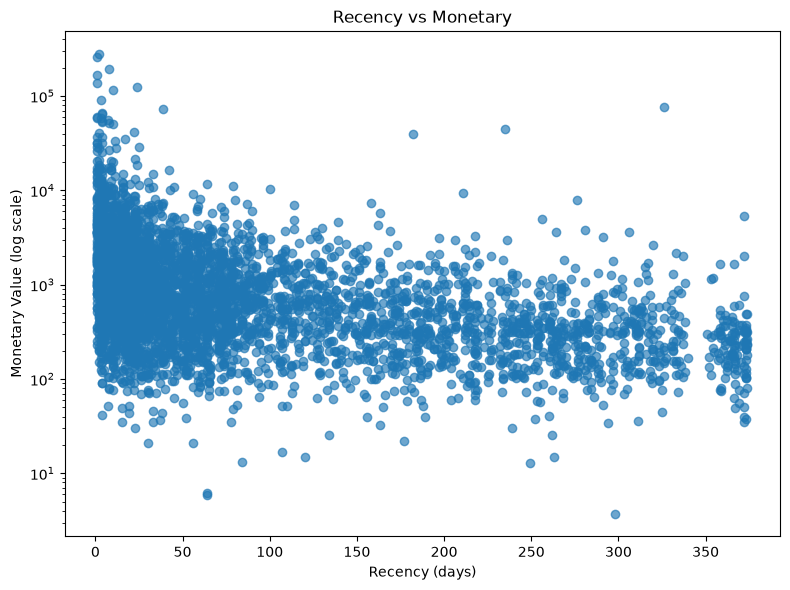

In [ ]:
# Recency vs Monetary Curve
plt.figure(figsize=(8, 6))
plt.scatter(rfm_table_cleaned["Recency"], rfm_table_cleaned["Monetary"], alpha=0.65)
plt.yscale("log")
plt.title("Recency vs Monetary")
plt.xlabel("Recency (days)")
plt.ylabel("Monetary Value (log scale)")
plt.tight_layout()
plt.show()

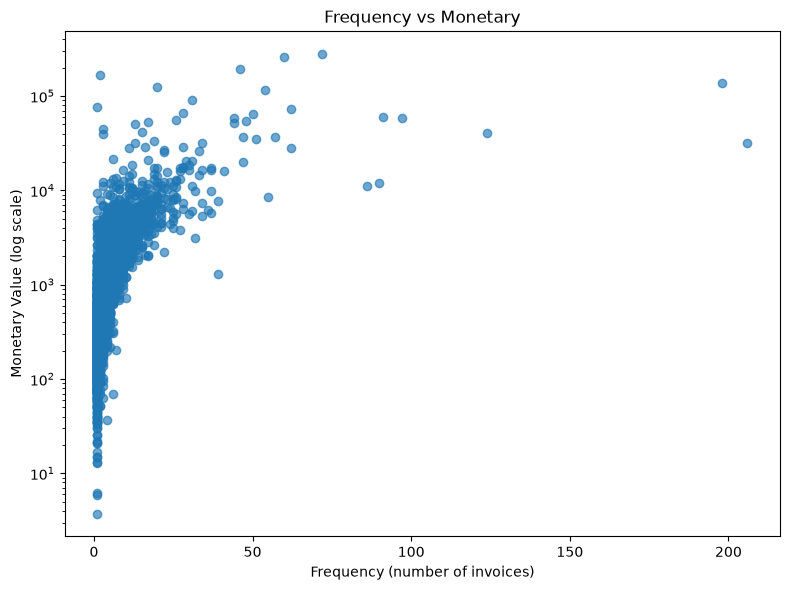

In [ ]:
# Frequency vs Monetary Curve 
plt.figure(figsize=(8, 6))
plt.scatter(rfm_table_cleaned["Frequency"], rfm_table_cleaned["Monetary"], alpha=0.65)
plt.yscale("log")
plt.title("Frequency vs Monetary")
plt.xlabel("Frequency (number of invoices)")
plt.ylabel("Monetary Value (log scale)")
plt.tight_layout()
plt.show()

In [ ]:
# Preparing RFM features for clustering
data = rfm_table_cleaned[["CustomerID", "Recency", "Frequency", "Monetary"]].copy()
rfm_features = data[["Recency", "Frequency", "Monetary"]]

sc = StandardScaler()
data_scaled = sc.fit_transform(rfm_features)

print("Scaled feature shape:", data_scaled.shape)
print("Feature names:", rfm_features.columns.tolist())

Scaled feature shape: (4334, 3)
Feature names: ['Recency', 'Frequency', 'Monetary']


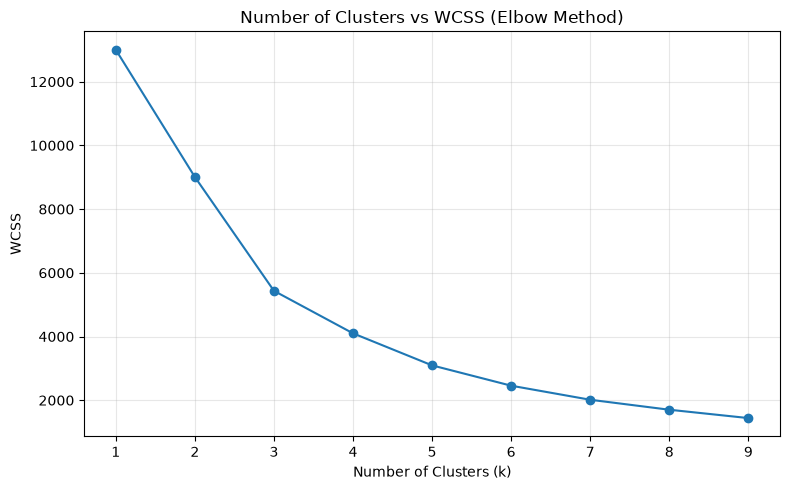

In [64]:
# K-Means: Elbow method(sum of square error)
sse = []
cluster_range = range(1, 10)

for k in cluster_range:
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(data_scaled)
    sse.append(kmeans_model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), sse, marker="o")
plt.title("Number of Clusters vs WCSS (Elbow Method)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(list(cluster_range))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred_kmeans = kmeans.fit_predict(data_scaled)

data_kmeans = data.copy()
data_kmeans["KMeans_Cluster"] = y_pred_kmeans

print("K-Means cluster labels:", np.unique(y_pred_kmeans))
print("Customers in each K-Means cluster:")
display(data_kmeans["KMeans_Cluster"].value_counts().sort_index().to_frame("Customer_Count"))

print("RFM summary by K-Means cluster:")
display(data_kmeans.groupby("KMeans_Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2))

K-Means cluster labels: [0 1 2]
Customers in each K-Means cluster:


,Customer_Count
KMeans_Cluster,
0,3225
1,1084
2,25


RFM summary by K-Means cluster:


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,41.42,4.65,1833.64
1,247.28,1.57,624.75
2,6.12,67.84,85859.88


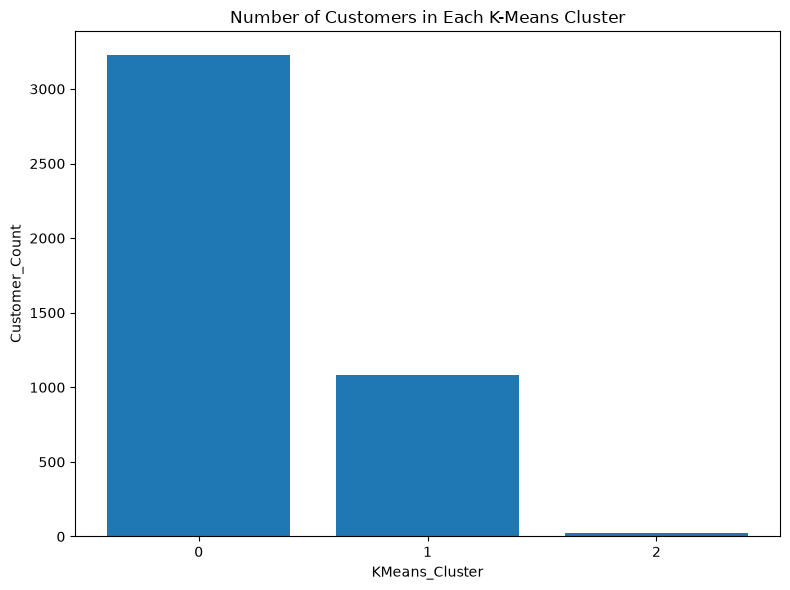

In [71]:
#Visualization: K-Means cluster sizes
kmeans_counts = data_kmeans["KMeans_Cluster"].value_counts().sort_index().rename_axis("KMeans_Cluster").reset_index(name="Customer_Count")
plt.figure(figsize=(8, 6))
plt.bar(kmeans_counts["KMeans_Cluster"].astype(str), kmeans_counts["Customer_Count"])
plt.title("Number of Customers in Each K-Means Cluster")
plt.xlabel("KMeans_Cluster")
plt.ylabel("Customer_Count")
plt.tight_layout()
plt.show()

In [ ]:
db = DBSCAN(eps=0.5, min_samples=5)
y_pred_db = db.fit_predict(data_scaled)

data_db_05 = data.copy()
data_db_05["DBSCAN_Cluster"] = y_pred_db

print("DBSCAN labels (including -1 for noise):", np.unique(y_pred_db))
print("Customers in each DBSCAN label:")
display(data_db_05["DBSCAN_Cluster"].value_counts().sort_index().to_frame("Customer_Count"))

print("RFM descriptive statistics by DBSCAN label:")
display(data_db_05.groupby("DBSCAN_Cluster")[["Recency", "Frequency", "Monetary"]].describe().T)

DBSCAN labels (including -1 for noise): [-1  0]
Customers in each DBSCAN label:


,Customer_Count
DBSCAN_Cluster,
-1,55
0,4279


RFM descriptive statistics by DBSCAN label:


DBSCAN_Cluster              -1             0
Recency   count      55.000000   4279.000000
          mean       42.981818     93.342136
          std        91.529491    100.132513
          min         1.000000      1.000000
          25%         2.000000     18.000000
          50%         4.000000     52.000000
          75%        19.000000    144.000000
          max       372.000000    374.000000
Frequency count      55.000000   4279.000000
          mean       42.727273      3.751344
          std        41.151236      4.287675
          min         1.000000      1.000000
          25%        16.500000      1.000000
          50%        34.000000      2.000000
          75%        52.500000      4.000000
          max       206.000000     39.000000
Monetary  count      55.000000   4279.000000
          mean    52697.738364   1364.536581
          std     58181.750410   2029.062007
          min      1296.440000      3.750000
          25%     18493.475000    301.950000
          50%     33643.080000    653.190000
          75%     58396.280000   1569.780000
          max    279138.020000  20374.280000

In [24]:
db_04 = DBSCAN(eps=0.4, min_samples=5)
y_pred_db_04 = db_04.fit_predict(data_scaled)

data_db_04 = data.copy()
data_db_04["DBSCAN_Cluster"] = y_pred_db_04

print("DBSCAN labels for eps=0.4 (including -1 for noise):", np.unique(y_pred_db_04))
display(data_db_04["DBSCAN_Cluster"].value_counts().sort_index().to_frame("Customer_Count"))
print("RFM descriptive statistics by DBSCAN label (eps=0.4):")
display(data_db_04.groupby("DBSCAN_Cluster")[["Recency", "Frequency", "Monetary"]].describe().T)

DBSCAN labels for eps=0.4 (including -1 for noise): [-1  0]


,Customer_Count
DBSCAN_Cluster,
-1,71
0,4263


RFM descriptive statistics by DBSCAN label (eps=0.4):


DBSCAN_Cluster              -1             0
Recency   count      71.000000   4263.000000
          mean       46.563380     93.471499
          std        86.327240    100.220581
          min         1.000000      1.000000
          25%         2.000000     18.000000
          50%         7.000000     52.000000
          75%        24.500000    144.500000
          max       372.000000    374.000000
Frequency count      71.000000   4263.000000
          mean       38.098592      3.682149
          std        37.608569      4.077335
          min         1.000000      1.000000
          25%        13.500000      1.000000
          50%        33.000000      2.000000
          75%        47.000000      4.000000
          max       206.000000     32.000000
Monetary  count      71.000000   4263.000000
          mean    42759.537606   1337.391619
          std     54407.901537   1965.162414
          min      1296.440000      3.750000
          25%      9772.615000    301.160000
          50%     26626.800000    648.700000
          75%     52392.865000   1554.005000
          max    279138.020000  20374.280000

In [59]:
# Reducing dimensions with PCA
pca = PCA(n_components=2, random_state=42)
rfm_pca = pca.fit_transform(data_scaled)

pca_data = data.copy()
pca_data["PCA1"] = rfm_pca[:, 0]
pca_data["PCA2"] = rfm_pca[:, 1]
pca_data["KMeans_Cluster"] = y_pred_kmeans
pca_data["DBSCAN_eps_05"] = y_pred_db
pca_data["DBSCAN_eps_04"] = y_pred_db_04

print("Explained variance ratio for the two principal components:", pca.explained_variance_ratio_)
print("Total variance represented in 2D:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")
display(pca_data.head())

Explained variance ratio for the two principal components: [0.55323304 0.30251578]
Total variance represented in 2D: 85.57 %


,CustomerID,Recency,Frequency,Monetary,PCA1,PCA2,KMeans_Cluster,DBSCAN_eps_05,DBSCAN_eps_04
0,12346,326,1,77183.60,4.145342,5.500315,1,-1,-1
1,12347,2,7,4310.00,0.752765,-0.665509,0,0,0
2,12348,75,4,1437.24,0.004932,-0.190416,0,0,0
3,12349,19,1,1457.55,-0.044847,-0.745709,0,0,0
4,12350,310,1,294.40,-1.239656,1.824947,1,0,0


## 26. PCA visualization: K-Means clusters

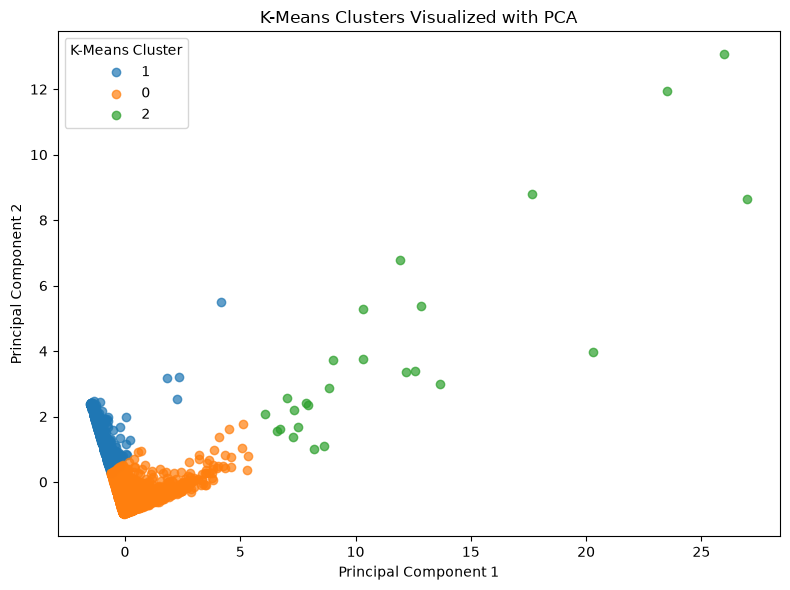

In [60]:
# PCA Graph: K-Means clusters
plt.figure(figsize=(8, 6))
for cluster in pca_data["KMeans_Cluster"].astype(str).unique():
    mask = pca_data["KMeans_Cluster"].astype(str) == cluster
    plt.scatter(pca_data.loc[mask, "PCA1"], pca_data.loc[mask, "PCA2"], label=cluster, alpha=0.7)
plt.title("K-Means Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="K-Means Cluster")
plt.tight_layout()
plt.show()

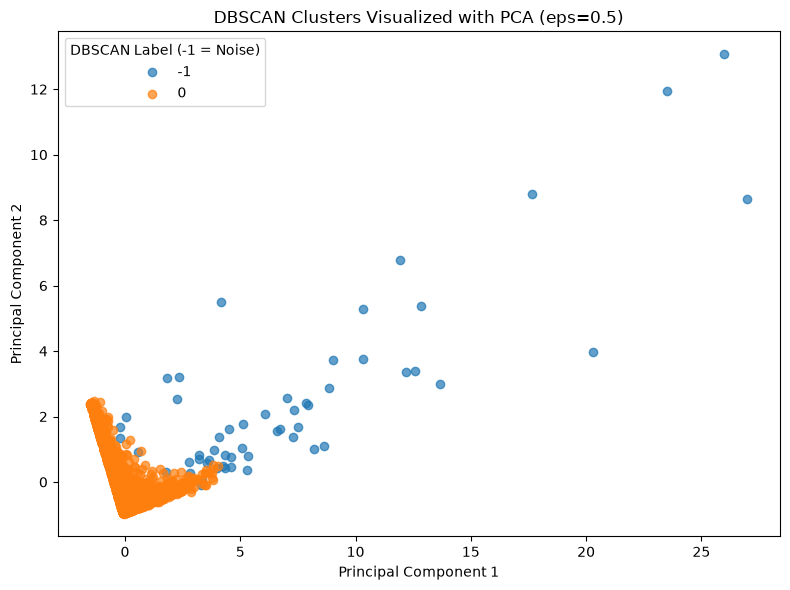

In [ ]:
# PCA graph: DBSCAN (eps = 0.5)
plt.figure(figsize=(8, 6))
for cluster in pca_data["DBSCAN_eps_05"].astype(str).unique():
    mask = pca_data["DBSCAN_eps_05"].astype(str) == cluster
    plt.scatter(pca_data.loc[mask, "PCA1"], pca_data.loc[mask, "PCA2"], label=cluster, alpha=0.7)
plt.title("DBSCAN Clusters Visualized with PCA (eps=0.5)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="DBSCAN Label (-1 = Noise)")
plt.tight_layout()
plt.show()

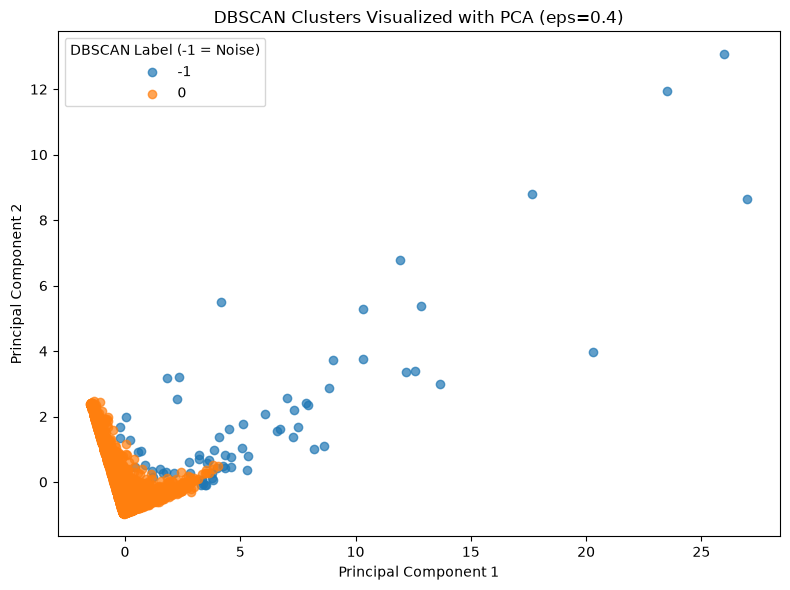

In [ ]:
# PCA graph: DBSCAN (eps = 0.4)
plt.figure(figsize=(8, 6))
for cluster in pca_data["DBSCAN_eps_04"].astype(str).unique():
    mask = pca_data["DBSCAN_eps_04"].astype(str) == cluster
    plt.scatter(pca_data.loc[mask, "PCA1"], pca_data.loc[mask, "PCA2"], label=cluster, alpha=0.7)
plt.title("DBSCAN Clusters Visualized with PCA (eps=0.4)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="DBSCAN Label (-1 = Noise)")
plt.tight_layout()
plt.show()

In [70]:
pca_data

,CustomerID,Recency,Frequency,Monetary,PCA1,PCA2,KMeans_Cluster,DBSCAN_eps_05,DBSCAN_eps_04
0,12346,326,1,77183.60,4.145342,5.500315,1,-1,-1
1,12347,2,7,4310.00,0.752765,-0.665509,0,0,0
2,12348,75,4,1437.24,0.004932,-0.190416,0,0,0
3,12349,19,1,1457.55,-0.044847,-0.745709,0,0,0
4,12350,310,1,294.40,-1.239656,1.824947,1,0,0
...,...,...,...,...,...,...,...,...,...
4329,18280,278,1,180.60,-1.125389,1.531163,1,0,0
4330,18281,181,1,80.82,-0.761649,0.651889,1,0,0
4331,18282,8,2,178.05,-0.004995,-0.886578,0,0,0
4332,18283,4,16,2039.58,1.380176,-0.597991,0,0,0


In [72]:
pca_data.head(10)

,CustomerID,Recency,Frequency,Monetary,PCA1,PCA2,KMeans_Cluster,DBSCAN_eps_05,DBSCAN_eps_04
0,12346,326,1,77183.60,4.145342,5.500315,1,-1,-1
1,12347,2,7,4310.00,0.752765,-0.665509,0,0,0
2,12348,75,4,1437.24,0.004932,-0.190416,0,0,0
3,12349,19,1,1457.55,-0.044847,-0.745709,0,0,0
4,12350,310,1,294.40,-1.239656,1.824947,1,0,0
5,12352,36,7,1385.74,0.415662,-0.493211,0,0,0
6,12353,204,1,89.00,-0.848993,0.859666,1,0,0
7,12354,232,1,1079.40,-0.885879,1.157637,1,0,0
8,12355,214,1,459.40,-0.860985,0.966851,1,0,0
9,12356,23,3,2487.43,0.189671,-0.628176,0,0,0


In [73]:
final_results = pca_data.copy()
final_results.to_csv("final.csv", index=False)
display(final_results.head(10))

,CustomerID,Recency,Frequency,Monetary,PCA1,PCA2,KMeans_Cluster,DBSCAN_eps_05,DBSCAN_eps_04
0,12346,326,1,77183.60,4.145342,5.500315,1,-1,-1
1,12347,2,7,4310.00,0.752765,-0.665509,0,0,0
2,12348,75,4,1437.24,0.004932,-0.190416,0,0,0
3,12349,19,1,1457.55,-0.044847,-0.745709,0,0,0
4,12350,310,1,294.40,-1.239656,1.824947,1,0,0
5,12352,36,7,1385.74,0.415662,-0.493211,0,0,0
6,12353,204,1,89.00,-0.848993,0.859666,1,0,0
7,12354,232,1,1079.40,-0.885879,1.157637,1,0,0
8,12355,214,1,459.40,-0.860985,0.966851,1,0,0
9,12356,23,3,2487.43,0.189671,-0.628176,0,0,0
